In [1]:
from obspy import read

In [2]:
import numpy as np

import matplotlib.pyplot as plt

import glob

from obspy import read

from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.signal import spectrogram
from dtaidistance import dtw
from sklearn.metrics import silhouette_score
from pyclustering.cluster.kmedians import kmedians
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score

import pandas as pd


In [3]:
files = glob.glob("*.SAC")

print("Files found:", len(files))

Files found: 61


In [4]:
import os

print(os.getcwd())

/home/dorsa/seismic_project


In [5]:
def preprocess_signal(tr, band):

    tr = tr.copy()

    tr.detrend("linear")

    tr.detrend("demean")

    if band == "low":

        tr.filter("bandpass", freqmin=0.1, freqmax=1)

    elif band == "medium":

        tr.filter("bandpass", freqmin=1, freqmax=5)

    elif band == "high":

        tr.filter("bandpass", freqmin=5, freqmax=10)

    return tr.data

In [6]:
def normalize_signal(signal):

    return (signal - np.mean(signal)) / np.std(signal)

In [7]:
signals = []
sampling_rates = []

selected_band = "medium"

for file in files:

    print("Loading:", file)

    st = read(file)

    tr = st[0]

    signal = preprocess_signal(
        tr,
        selected_band
    )

    signal = normalize_signal(signal)

    signals.append(signal)
    sampling_rates.append(tr.stats.sampling_rate)

print("Loaded signals:", len(signals))
print("Sampling rates:", sorted(set(sampling_rates)))

Loading: GE.APE..BHZ.SAC
Loading: GE.HLG..BHZ.SAC
Loading: GE.DAG..BHZ (1).SAC
Loading: DK.GDH..BHZ.SAC
Loading: GE.ISP..BHZ (1).SAC
Loading: DK.ANGG..BHZ (1).SAC
Loading: GE.GVD..BHZ (2).SAC
Loading: DK.NUUK..BHZ (1).SAC
Loading: GE.CSS..BHZ (1).SAC
Loading: GE.ISP..BHZ.SAC
Loading: GE.GHAR..BHZ (2).SAC
Loading: GE.KRIS..BHZ.SAC
Loading: GE.DSB..BHZ (3).SAC
Loading: GE.FODE..BHZ.SAC
Loading: GE.DSB..BHZ.SAC
Loading: GE.FODE..BHZ (1).SAC
Loading: GE.IBBN..BHZ.SAC
Loading: GE.DAG..BHZ.SAC
Loading: DK.ANGG..BHZ (4).SAC
Loading: GE.DAG..BHZ (3).SAC
Loading: DK.ANGG..BHZ (3).SAC
Loading: GE.KRIS..BHZ (1).SAC
Loading: GE.CSS..BHZ (3).SAC
Loading: GE.MORC..BHZ.SAC
Loading: GE.GHAR..BHZ (1).SAC
Loading: 1999.09.26.0940.VSL.BHZ.SAC
Loading: DK.PAAG..BHZ (1).SAC
Loading: GE.APE..BHZ (1).SAC
Loading: GE.CSS..BHZ.SAC
Loading: 1999.09.26.0940.VSL.BHZ (1).SAC
Loading: GE.HLG..BHZ (2).SAC
Loading: GE.ISP..BHZ (3).SAC
Loading: DK.TULEG..HHZ.SAC
Loading: GE.MELI..BHZ.SAC
Loading: DK.GDH..BHZ (1).SAC
L

In [8]:
min_len = min(len(s) for s in signals)

signals = [s[:min_len] for s in signals]

print("Trimmed length:", min_len)

Trimmed length: 4800


In [9]:
corr_matrix = np.corrcoef(signals)

print(corr_matrix.shape)

(61, 61)


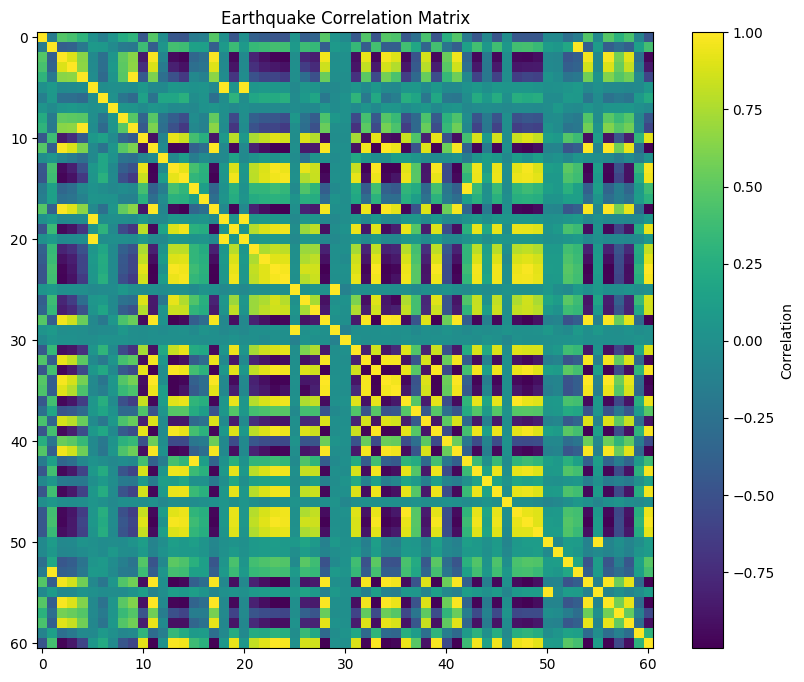

In [10]:
plt.figure(figsize=(10,8))

plt.imshow(corr_matrix)

plt.colorbar(label="Correlation")

plt.title("Earthquake Correlation Matrix")

plt.show()

In [11]:
def extract_features(signal, sampling_rate=1.0):
    """
    Extract time-domain and one-sided frequency-domain features.

    Important fix:
    - Uses np.fft.rfft / np.fft.rfftfreq, so only non-negative physical
      frequencies are used.
    - Uses frequency masks for low/mid/high band energy instead of slicing the
      two-sided FFT array.
    """

    signal = np.asarray(signal)
    eps = 1e-12

    # Time-domain features
    rms = np.sqrt(np.mean(signal**2))
    peak = np.max(np.abs(signal))

    if peak > eps:
        duration = np.sum(np.abs(signal) > 0.1 * peak)
    else:
        duration = 0

    # One-sided frequency-domain features
    spectrum = np.fft.rfft(signal)
    magnitude = np.abs(spectrum)
    freqs = np.fft.rfftfreq(len(signal), d=1.0 / sampling_rate)

    mag_sum = np.sum(magnitude) + eps

    spectral_centroid = np.sum(freqs * magnitude) / mag_sum

    bandwidth = np.sqrt(
        np.sum(((freqs - spectral_centroid)**2) * magnitude) / mag_sum
    )

    # Band energy ratios across the positive-frequency range
    max_freq = freqs[-1]

    low_mask = freqs <= max_freq / 3
    mid_mask = (freqs > max_freq / 3) & (freqs <= 2 * max_freq / 3)
    high_mask = freqs > 2 * max_freq / 3

    total_energy = np.sum(magnitude**2) + eps
    low_energy = np.sum(magnitude[low_mask]**2) / total_energy
    mid_energy = np.sum(magnitude[mid_mask]**2) / total_energy
    high_energy = np.sum(magnitude[high_mask]**2) / total_energy

    return [
        rms,
        peak,
        duration,
        spectral_centroid,
        bandwidth,
        low_energy,
        mid_energy,
        high_energy
    ]

In [12]:
features = []

# Use the first sampling rate if all traces have the same sampling rate.
# If they differ, consider resampling before comparing frequency features.
sampling_rate = sampling_rates[0]

for signal in signals:

    f = extract_features(signal, sampling_rate=sampling_rate)

    features.append(f)

X = np.array(features)

print(X.shape)

(61, 8)


In [13]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(61, 8)


In [14]:
db = DBSCAN(eps=1.5, min_samples=2)

db_labels = db.fit_predict(X_scaled)

print(db_labels)


[-1  0  0  0  0  1  0  1  0  0  0  0  0  0  0  0 -1  0  1  0  1  0  0  0
  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0 -1  0  0  0 -1  0 -1  0
  0  0  1  1  0  0  0  1  0  0  0  0  0]


In [15]:
kmeans = KMeans(n_clusters=3)

kmeans_labels = kmeans.fit_predict(X_scaled)

print(kmeans_labels)

[1 1 2 0 1 1 1 1 1 1 0 2 1 2 2 1 1 2 1 0 1 0 0 2 2 1 0 0 2 1 1 0 2 2 2 2 0
 1 0 2 1 2 1 0 1 0 1 0 2 0 1 1 1 1 2 1 2 1 0 1 2]


In [16]:
hierarchical = AgglomerativeClustering(
    n_clusters=3
)

hierarchical_labels = hierarchical.fit_predict(
    X_scaled
)

print(hierarchical_labels)

[1 1 0 1 1 2 1 2 1 1 0 0 1 0 0 1 1 0 2 0 2 0 0 0 0 1 0 1 0 1 2 0 0 0 0 0 0
 1 0 0 1 0 1 0 1 0 2 0 0 0 2 2 1 1 0 2 0 1 0 1 0]


In [17]:
initial_medians = X_scaled[:3]

kmedians_instance = kmedians(X_scaled, initial_medians)

kmedians_instance.process()

kmedians_clusters = kmedians_instance.get_clusters()

print(kmedians_clusters)

[[40, 0, 46, 44], [27, 3, 57, 12, 37, 25, 29, 59, 6, 15, 42, 16, 8, 50, 55, 20, 5, 18, 51, 30, 7, 52, 4, 9, 1, 53], [17, 28, 34, 56, 35, 11, 54, 60, 23, 33, 13, 24, 39, 41, 48, 14, 2, 32, 26, 43, 38, 45, 36, 47, 31, 21, 10, 19, 22, 49, 58]]


In [18]:
kmedians_labels = np.zeros(len(X_scaled))

for cluster_id, cluster in enumerate(kmedians_clusters):

    for index in cluster:

        kmedians_labels[index] = cluster_id

print(kmedians_labels)

[0. 1. 2. 1. 1. 1. 1. 1. 1. 1. 2. 2. 1. 2. 2. 1. 1. 2. 1. 2. 1. 2. 2. 2.
 2. 1. 2. 1. 2. 1. 1. 2. 2. 2. 2. 2. 2. 1. 2. 2. 0. 2. 1. 2. 0. 2. 0. 2.
 2. 2. 1. 1. 1. 1. 2. 1. 2. 1. 2. 1. 2.]


In [19]:
kmedians_labels = np.zeros(len(X_scaled))

for cluster_id, cluster in enumerate(kmedians_clusters):

    for index in cluster:

        kmedians_labels[index] = cluster_id

print(kmedians_labels)

[0. 1. 2. 1. 1. 1. 1. 1. 1. 1. 2. 2. 1. 2. 2. 1. 1. 2. 1. 2. 1. 2. 2. 2.
 2. 1. 2. 1. 2. 1. 1. 2. 2. 2. 2. 2. 2. 1. 2. 2. 0. 2. 1. 2. 0. 2. 0. 2.
 2. 2. 1. 1. 1. 1. 2. 1. 2. 1. 2. 1. 2.]


In [20]:
inertia_values = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(n_clusters=k)

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

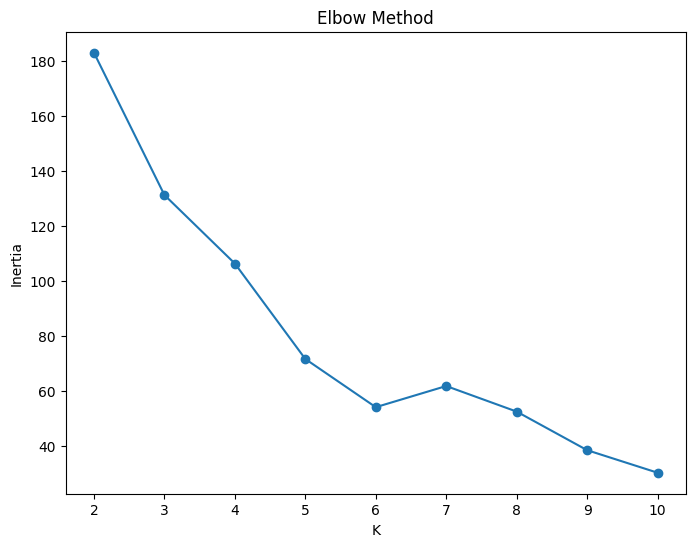

In [21]:
plt.figure(figsize=(8,6))

plt.plot(K_range, inertia_values, marker='o')

plt.xlabel("K")

plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.show()

In [22]:
score = silhouette_score(X_scaled, kmeans_labels)

print("Silhouette Score:", score)

Silhouette Score: 0.4041304914183494


In [23]:
silhouette_scores = []

for k in K_range:

    kmeans = KMeans(n_clusters=k)

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

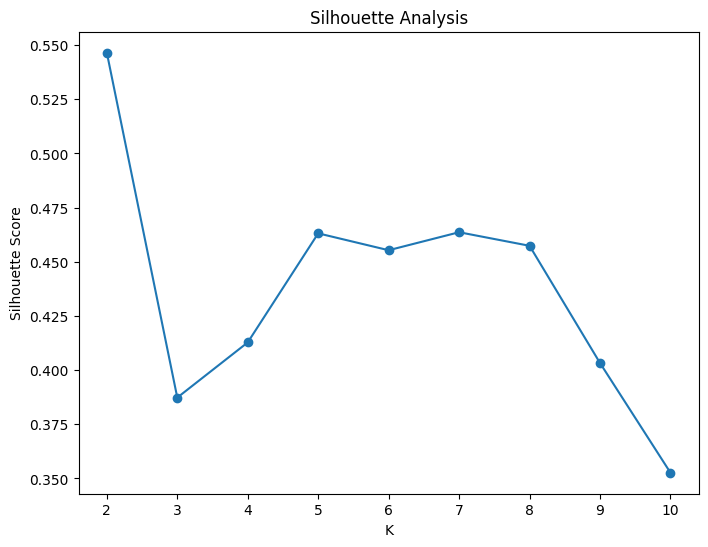

In [24]:
plt.figure(figsize=(8,6))

plt.plot(K_range, silhouette_scores, marker='o')

plt.xlabel("K")

plt.ylabel("Silhouette Score")

plt.title("Silhouette Analysis")

plt.show()

In [25]:
kmeans_score = silhouette_score(X_scaled, kmeans_labels)

kmedians_score = silhouette_score(X_scaled, kmedians_labels)

print("KMeans Score:", kmeans_score)

print("K-Medians Score:", kmedians_score)

KMeans Score: 0.4041304914183494
K-Medians Score: 0.5227949545855602


In [26]:
best_k = K_range[np.argmax(silhouette_scores)]

print("Best K:", best_k)

Best K: 2


In [27]:
kmeans = KMeans(n_clusters=best_k)

kmeans_labels = kmeans.fit_predict(X_scaled)

In [28]:
from sklearn.decomposition import PCA

In [29]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(61, 2)


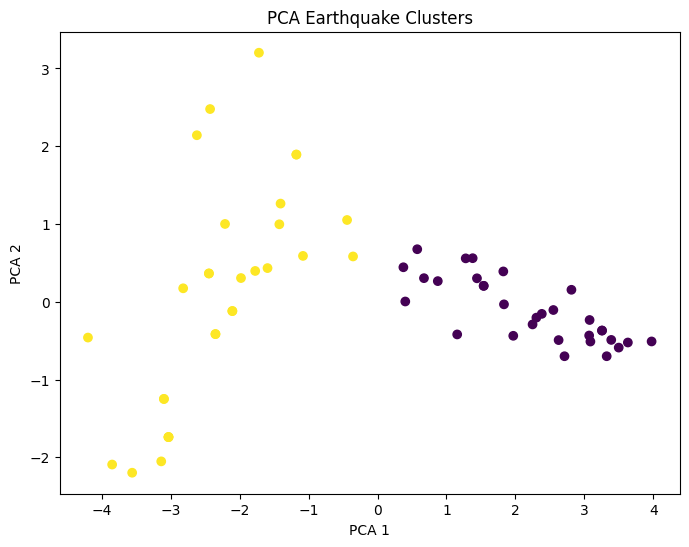

In [30]:
plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0], X_pca[:,1], c=kmeans_labels)

plt.title("PCA Earthquake Clusters")

plt.xlabel("PCA 1")

plt.ylabel("PCA 2")

plt.show()

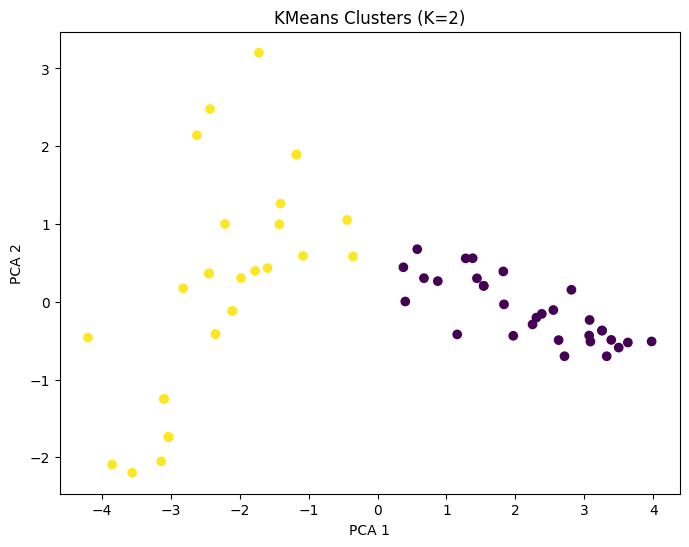

In [31]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0], X_pca[:,1], c=kmeans_labels)

plt.title(f"KMeans Clusters (K={best_k})")

plt.xlabel("PCA 1")

plt.ylabel("PCA 2")

plt.show()

In [32]:
hierarchical = AgglomerativeClustering(
    n_clusters=3
)

hierarchical_labels = hierarchical.fit_predict(
    X_scaled
)

print(hierarchical_labels)

[1 1 0 1 1 2 1 2 1 1 0 0 1 0 0 1 1 0 2 0 2 0 0 0 0 1 0 1 0 1 2 0 0 0 0 0 0
 1 0 0 1 0 1 0 1 0 2 0 0 0 2 2 1 1 0 2 0 1 0 1 0]


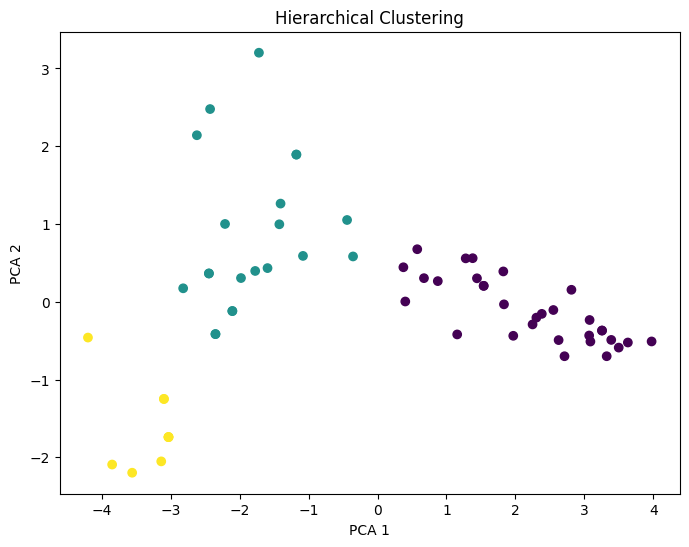

In [33]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=hierarchical_labels
)

plt.title("Hierarchical Clustering")

plt.xlabel("PCA 1")

plt.ylabel("PCA 2")

plt.show()

In [34]:
sil_score = silhouette_score(
    X_scaled,
    hierarchical_labels
)

db_score = davies_bouldin_score(
    X_scaled,
    hierarchical_labels
)

print("Silhouette Score:", sil_score)

print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.5192256835379008
Davies-Bouldin Index: 0.8053736148116085


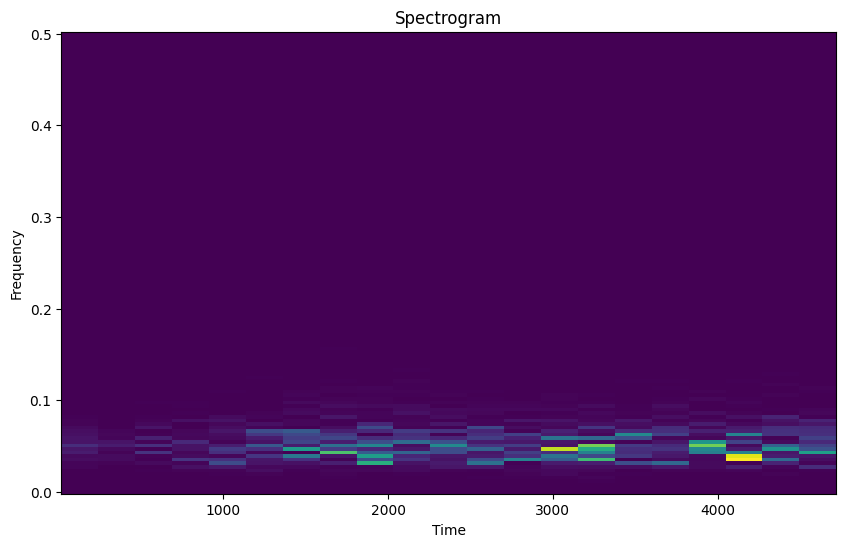

In [35]:
signal = signals[0]

f, t, Sxx = spectrogram(signal)

plt.figure(figsize=(10,6))

plt.pcolormesh(t, f, Sxx)

plt.ylabel('Frequency')

plt.xlabel('Time')

plt.title('Spectrogram')

plt.show()

In [36]:
signal = signals[0]

window_size = len(signal) // 3

part1 = signal[:window_size]

part2 = signal[window_size:2*window_size]

part3 = signal[2*window_size:]

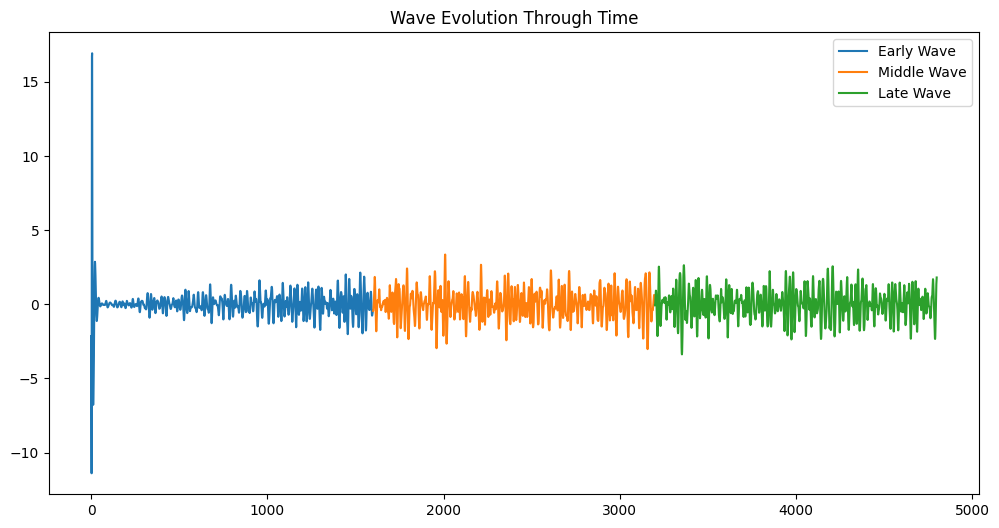

In [37]:
plt.figure(figsize=(12,6))

plt.plot(part1, label="Early Wave")

plt.plot(range(window_size, 2*window_size), part2, label="Middle Wave")

plt.plot(range(2*window_size, len(signal)), part3, label="Late Wave")

plt.legend()

plt.title("Wave Evolution Through Time")

plt.show()

In [38]:
signal1 = signals[0]

signal2 = signals[1]

distance = dtw.distance(signal1, signal2)

print("DTW Distance:", distance)

DTW Distance: 33.042095909010726


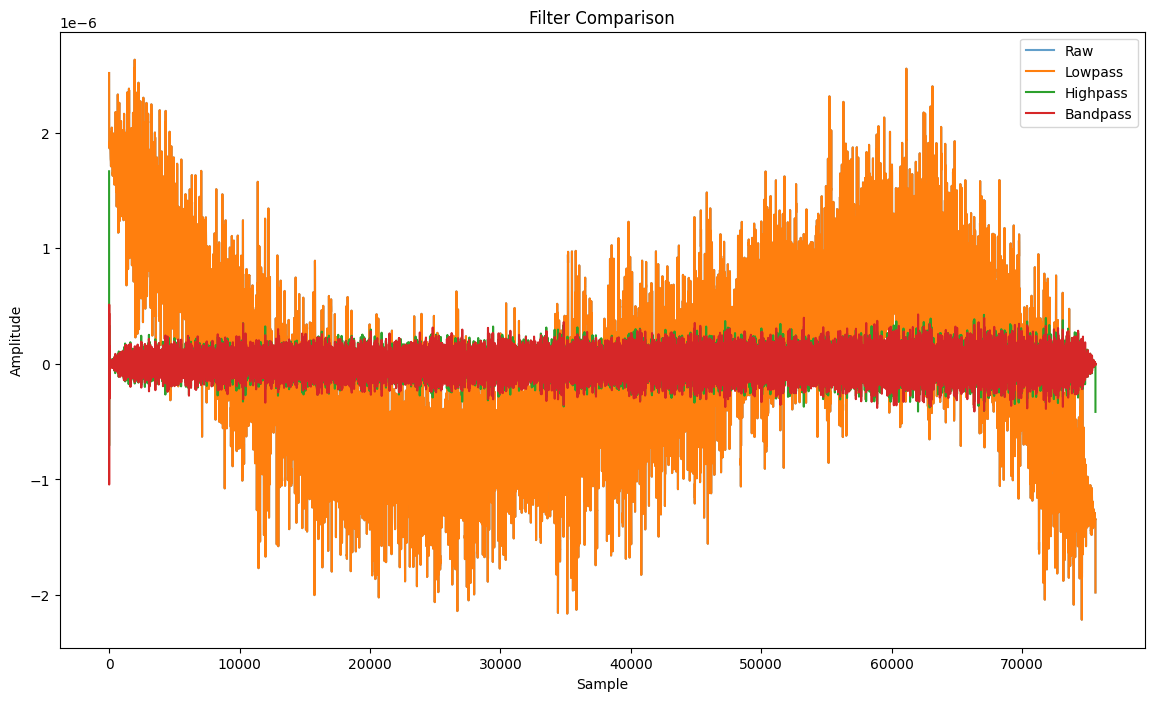

In [39]:
file = "GE.HLG..BHZ.SAC"

st = read(file)

tr_raw = st[0].copy()

tr_low = st[0].copy()

tr_high = st[0].copy()

tr_band = st[0].copy()

# Detrend
for tr in [tr_raw, tr_low, tr_high, tr_band]:

    tr.detrend("linear")

    tr.detrend("demean")

# Filters
tr_low.filter("lowpass", freq=2)

tr_high.filter("highpass", freq=1)

tr_band.filter("bandpass", freqmin=1, freqmax=8)

# Plot
plt.figure(figsize=(14,8))

plt.plot(tr_raw.data, label="Raw", alpha=0.7)

plt.plot(tr_low.data, label="Lowpass")

plt.plot(tr_high.data, label="Highpass")

plt.plot(tr_band.data, label="Bandpass")

plt.legend()

plt.title("Filter Comparison")

plt.xlabel("Sample")

plt.ylabel("Amplitude")

plt.show()

In [40]:
# Keep the original `signals` variable unchanged.
# This avoids accidentally switching the analysis from medium-band signals
# to lowpass-filtered signals halfway through the notebook.
lowpass_signals = []

for file in files:

    st = read(file)

    tr = st[0].copy()

    tr.detrend("linear")

    tr.detrend("demean")

    tr.filter("lowpass", freq=2)

    lowpass_signals.append(normalize_signal(tr.data))

# Equal lengths
min_len_lowpass = min(len(s) for s in lowpass_signals)

lowpass_signals = [s[:min_len_lowpass] for s in lowpass_signals]

# Lowpass-only correlation matrix, kept separate from the main correlation matrix
corr_matrix_lowpass = np.corrcoef(lowpass_signals)

print(corr_matrix_lowpass)

[[ 1.         -0.43054446  0.7923583  ...  0.32351457 -0.34235625
  -0.74420963]
 [-0.43054446  1.         -0.5216009  ... -0.2274831   0.25007913
   0.5053802 ]
 [ 0.7923583  -0.5216009   1.         ...  0.28670218 -0.4039333
  -0.93122793]
 ...
 [ 0.32351457 -0.2274831   0.28670218 ...  1.         -0.23234999
  -0.28545036]
 [-0.34235625  0.25007913 -0.4039333  ... -0.23234999  1.
   0.33592123]
 [-0.74420963  0.5053802  -0.93122793 ... -0.28545036  0.33592123
   1.        ]]


In [41]:
# Main-analysis correlation matrix remains based on `signals`, i.e. the selected band.
corr_matrix = np.corrcoef(signals)

print(corr_matrix)

[[ 1.         -0.43054446  0.7923583  ...  0.32351457 -0.34235625
  -0.74420963]
 [-0.43054446  1.         -0.5216009  ... -0.2274831   0.25007913
   0.5053802 ]
 [ 0.7923583  -0.5216009   1.         ...  0.28670218 -0.4039333
  -0.93122793]
 ...
 [ 0.32351457 -0.2274831   0.28670218 ...  1.         -0.23234999
  -0.28545036]
 [-0.34235625  0.25007913 -0.4039333  ... -0.23234999  1.
   0.33592123]
 [-0.74420963  0.5053802  -0.93122793 ... -0.28545036  0.33592123
   1.        ]]


# Time-Series Window Analysis

In [42]:
signal = signals[0]

print(len(signal))

4800


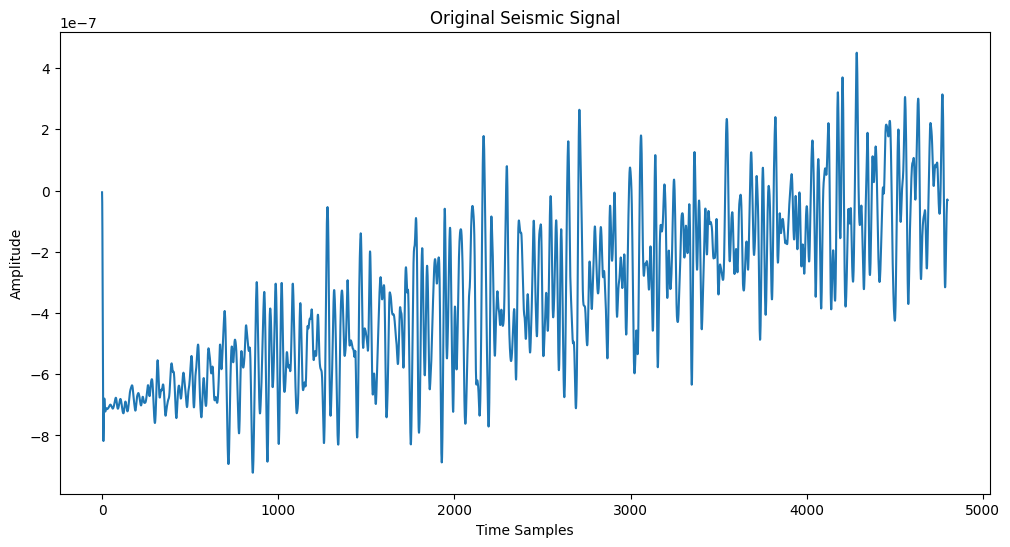

In [43]:
plt.figure(figsize=(12,6))

plt.plot(signal)

plt.title("Original Seismic Signal")

plt.xlabel("Time Samples")

plt.ylabel("Amplitude")

plt.show()

In [44]:
window_size = len(signal) // 3

part1 = signal[:window_size]

part2 = signal[window_size:2*window_size]

part3 = signal[2*window_size:]

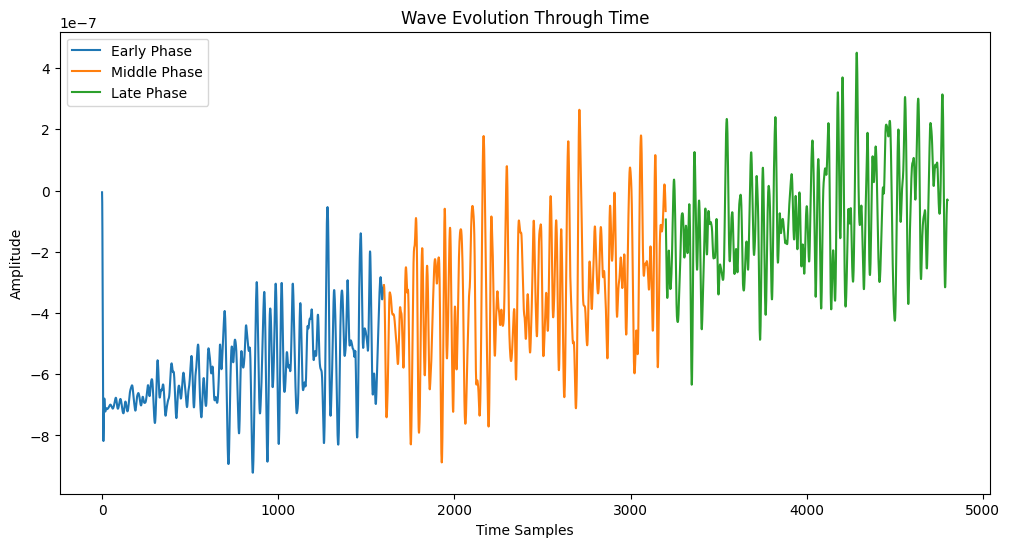

In [45]:
plt.figure(figsize=(12,6))

plt.plot(part1, label="Early Phase")

plt.plot(
    range(window_size, 2*window_size),
    part2,
    label="Middle Phase"
)

plt.plot(
    range(2*window_size, len(signal)),
    part3,
    label="Late Phase"
)

plt.legend()

plt.title("Wave Evolution Through Time")

plt.xlabel("Time Samples")

plt.ylabel("Amplitude")

plt.show()

In [46]:
def extract_window_features(segment):

    mean = np.mean(segment)

    std = np.std(segment)

    peak = np.max(np.abs(segment))

    energy = np.sum(segment**2)

    return [mean, std, peak, energy]

In [47]:
features_part1 = extract_window_features(part1)

features_part2 = extract_window_features(part2)

features_part3 = extract_window_features(part3)

print("Early Phase:", features_part1)

print("Middle Phase:", features_part2)

print("Late Phase:", features_part3)

Early Phase: [np.float64(-5.8162771279344e-07), np.float64(1.415246981659564e-07), np.float64(9.217354549841628e-07), np.float64(5.733120583684692e-10)]
Middle Phase: [np.float64(-3.346242102660896e-07), np.float64(2.0717794029170136e-07), np.float64(8.880163002065444e-07), np.float64(2.4783369766354554e-10)]
Late Phase: [np.float64(-9.221351430603536e-08), np.float64(1.772631592199606e-07), np.float64(6.341836350963167e-07), np.float64(6.388089573969679e-11)]


In [48]:
window_features = []

for signal in signals:

    window_size = len(signal) // 3

    part1 = signal[:window_size]

    part2 = signal[window_size:2*window_size]

    part3 = signal[2*window_size:]

    f1 = extract_window_features(part1)

    f2 = extract_window_features(part2)

    f3 = extract_window_features(part3)

    combined = f1 + f2 + f3

    window_features.append(combined)

window_features = np.array(window_features)

print(window_features.shape)

(61, 12)


In [49]:
scaler = StandardScaler()

window_scaled = scaler.fit_transform(window_features)

print(window_scaled.shape)

(61, 12)


In [50]:
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(n_clusters=k)

    labels = kmeans.fit_predict(window_scaled)

    score = silhouette_score(window_scaled, labels)

    silhouette_scores.append(score)

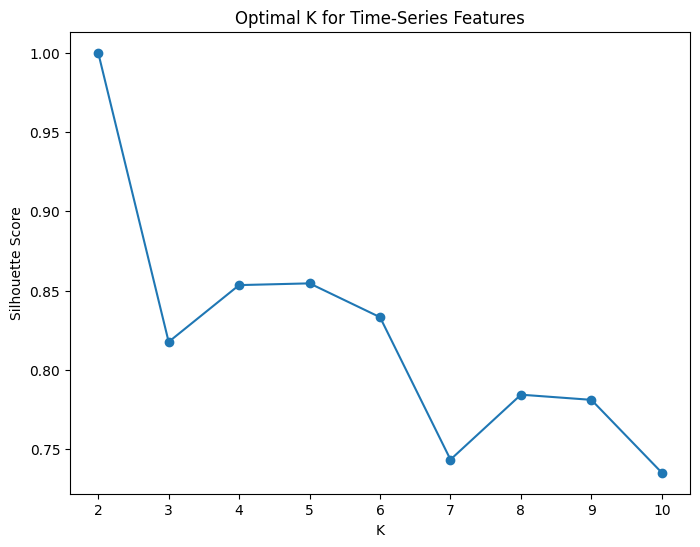

In [51]:
plt.figure(figsize=(8,6))

plt.plot(K_range, silhouette_scores, marker='o')

plt.xlabel("K")

plt.ylabel("Silhouette Score")

plt.title("Optimal K for Time-Series Features")

plt.show()

In [52]:
best_k = K_range[np.argmax(silhouette_scores)]

print("Best K:", best_k)

kmeans = KMeans(n_clusters=best_k)

labels = kmeans.fit_predict(window_scaled)

Best K: 2


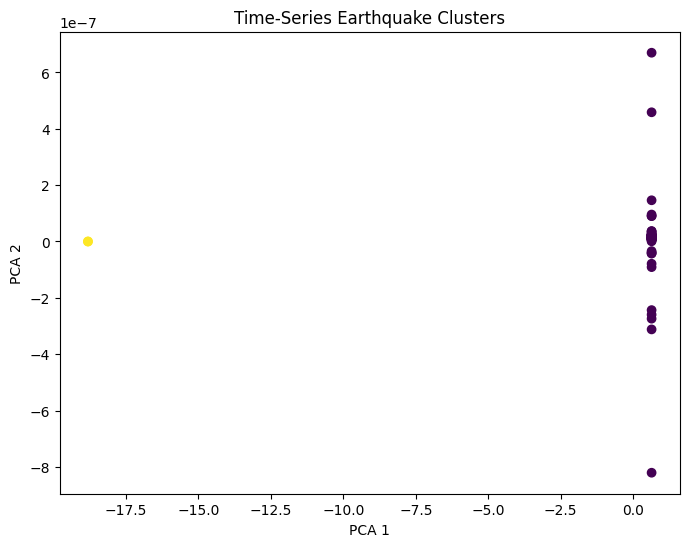

In [53]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(window_scaled)

plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0], X_pca[:,1], c=labels)

plt.title("Time-Series Earthquake Clusters")

plt.xlabel("PCA 1")

plt.ylabel("PCA 2")

plt.show()

# Spectrogram Analysis

In [54]:
f, t, Sxx = spectrogram(signal)

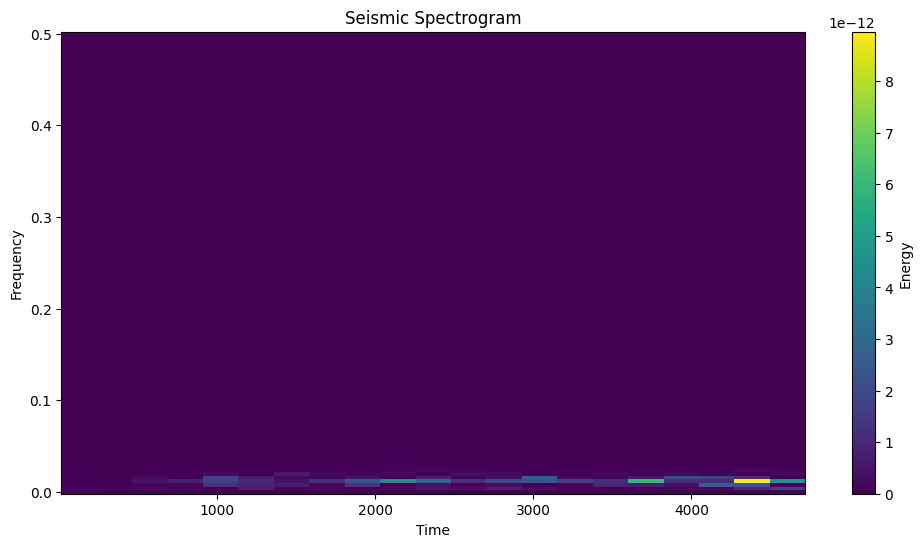

In [55]:
plt.figure(figsize=(12,6))

plt.pcolormesh(t, f, Sxx)

plt.ylabel('Frequency')

plt.xlabel('Time')

plt.title('Seismic Spectrogram')

plt.colorbar(label='Energy')

plt.show()

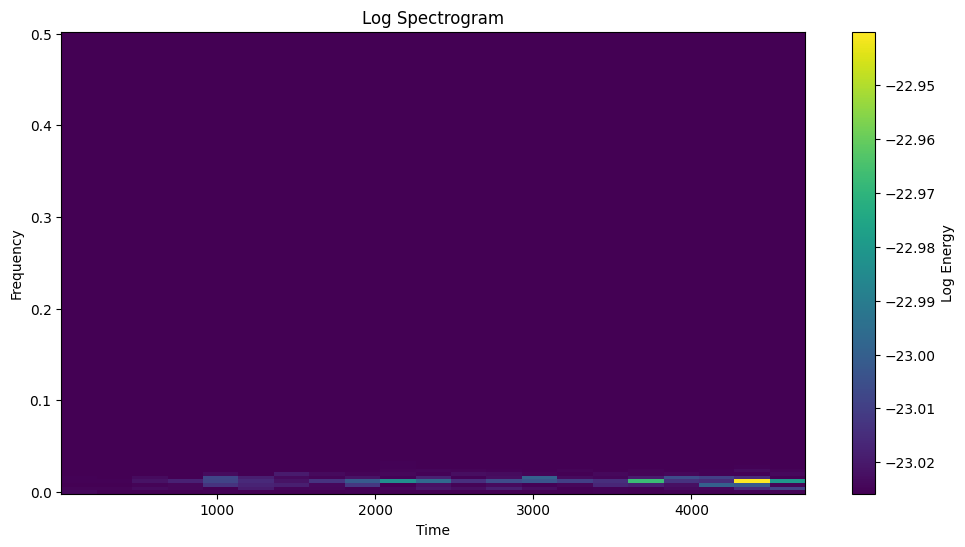

In [56]:
plt.figure(figsize=(12,6))

plt.pcolormesh(t, f, np.log(Sxx + 1e-10))

plt.ylabel('Frequency')

plt.xlabel('Time')

plt.title('Log Spectrogram')

plt.colorbar(label='Log Energy')

plt.show()

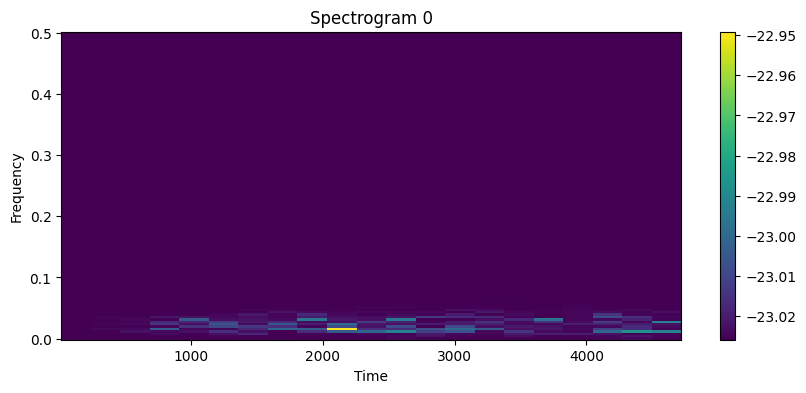

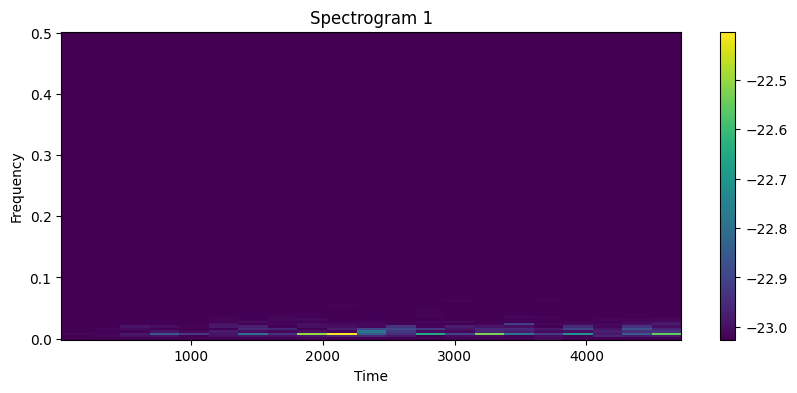

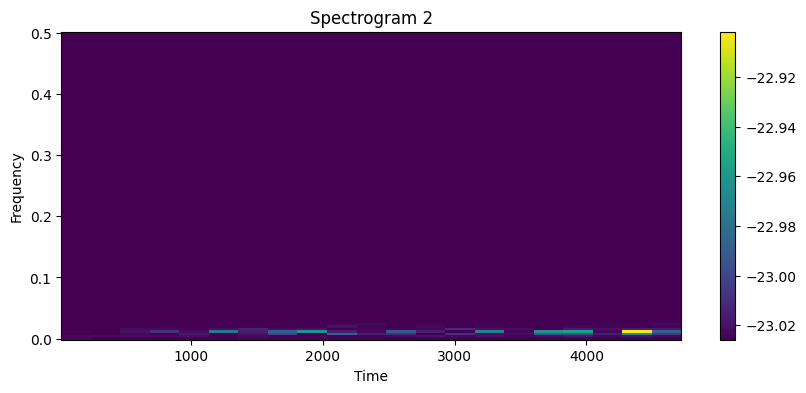

In [57]:
for i in range(3):

    signal = signals[i]

    f, t, Sxx = spectrogram(signal)

    plt.figure(figsize=(10,4))

    plt.pcolormesh(t, f, np.log(Sxx + 1e-10))

    plt.title(f"Spectrogram {i}")

    plt.ylabel("Frequency")

    plt.xlabel("Time")

    plt.colorbar()

    plt.show()

In [58]:
spectral_features = []

sampling_rate = sampling_rates[0]

eps = 1e-12

for signal in signals:

    spectrum = np.fft.rfft(signal)

    magnitude = np.abs(spectrum)

    freqs = np.fft.rfftfreq(len(signal), d=1.0 / sampling_rate)

    # Ignore DC when selecting the dominant frequency.
    if len(magnitude) > 1:
        dominant_freq = freqs[1:][np.argmax(magnitude[1:])]
    else:
        dominant_freq = 0.0

    mag_sum = np.sum(magnitude) + eps

    spectral_centroid = np.sum(freqs * magnitude) / mag_sum

    spectral_bandwidth = np.sqrt(
        np.sum(((freqs - spectral_centroid)**2) * magnitude) / mag_sum
    )

    spectral_features.append([
        dominant_freq,
        spectral_centroid,
        spectral_bandwidth
    ])

spectral_features = np.array(spectral_features)

print(spectral_features.shape)

(61, 3)


In [59]:
combined_features = np.hstack([window_features, spectral_features])

print(combined_features.shape)

(61, 15)


In [60]:
scaler = StandardScaler()

combined_scaled = scaler.fit_transform(combined_features)

In [61]:
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(n_clusters=k)

    labels = kmeans.fit_predict(combined_scaled)

    score = silhouette_score(combined_scaled, labels)

    silhouette_scores.append(score)

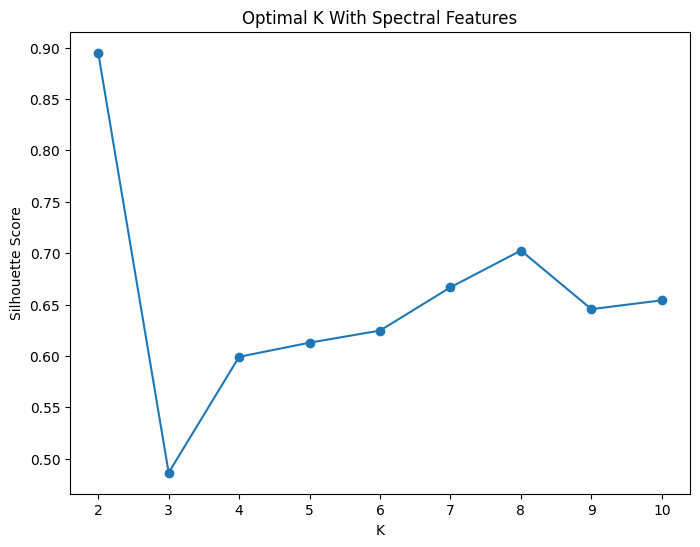

In [62]:
plt.figure(figsize=(8,6))

plt.plot(K_range, silhouette_scores, marker='o')

plt.xlabel("K")

plt.ylabel("Silhouette Score")

plt.title("Optimal K With Spectral Features")

plt.show()

In [63]:
best_k = K_range[np.argmax(silhouette_scores)]

print("Best K:", best_k)

kmeans = KMeans(n_clusters=best_k)

labels = kmeans.fit_predict(combined_scaled)


Best K: 2


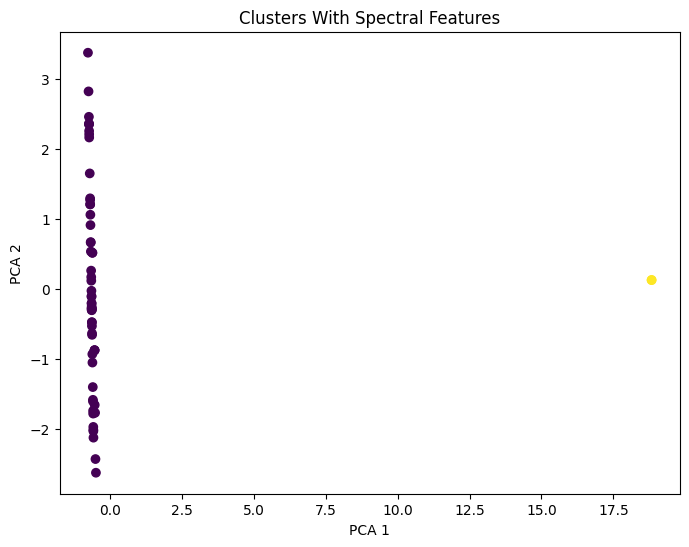

In [64]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(combined_scaled)

plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0], X_pca[:,1], c=labels)

plt.title("Clusters With Spectral Features")

plt.xlabel("PCA 1")

plt.ylabel("PCA 2")

plt.show()

In [ ]:
# Interpret the 2-cluster solution by comparing original feature means.
# This is the most important step before assigning physical meaning.

feature_names = [
    "rms",
    "peak",
    "duration",
    "spectral_centroid",
    "bandwidth",
    "low_energy_ratio",
    "mid_energy_ratio",
    "high_energy_ratio"
]

# Force the interpretable 2-cluster solution for the initial feature matrix X.
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=20)
labels_2 = kmeans_2.fit_predict(X_scaled)

cluster_summary = []

for c in np.unique(labels_2):
    idx = labels_2 == c
    row = {"cluster": c, "n_traces": int(np.sum(idx))}

    for name, value in zip(feature_names, X[idx].mean(axis=0)):
        row[name] = value

    cluster_summary.append(row)

cluster_summary = pd.DataFrame(cluster_summary)
print(cluster_summary)

print("\nFiles by cluster:")
for c in np.unique(labels_2):
    print(f"\nCluster {c}")
    for file, label in zip(files, labels_2):
        if label == c:
            print(file)

# Spectrogram Interpretation

In [65]:
signal1 = signals[0]

signal2 = signals[1]

distance = dtw.distance(signal1, signal2)

print("DTW Distance:", distance)

DTW Distance: 8.226749314816308e-05


In [ ]:
n = len(signals)

dtw_matrix = np.zeros((n, n))

for i in range(n):

    for j in range(n):

        dtw_matrix[i, j] = dtw.distance(
            signals[i],
            signals[j]
        )

print(dtw_matrix.shape)

In [ ]:
plt.figure(figsize=(10,8))

plt.imshow(dtw_matrix)

plt.colorbar(label="DTW Distance")

plt.title("DTW Similarity Matrix")

plt.show()

In [ ]:
clustering = AgglomerativeClustering(
    n_clusters=3,
    metric='precomputed',
    linkage='average'
)

labels = clustering.fit_predict(dtw_matrix)

print(labels)

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(dtw_matrix)

plt.figure(figsize=(8,6))

plt.scatter(X_pca[:,0], X_pca[:,1], c=labels)

plt.title("DTW-Based Clustering")

plt.xlabel("PCA 1")

plt.ylabel("PCA 2")

plt.show()